# Hierarchical Error Analysis

This notebook evaluates the types of classification errors made by KNN,
Random Forest, and MLP on the UJIIndoorLoc dataset.

The purpose of this analysis is to determine whether the models struggle
more with identifying the correct building or identifying the correct
floor within a building.

The same dataset, preprocessing steps, hyperparameters, and random seed
from the original model implementation are used to maintain consistency.

## 1. Import Libraries

In [24]:
%pip install numpy pandas matplotlib scikit-learn torch


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

import torch
import torch.nn as nn

## 2. Load the Dataset

The cleaned training and validation datasets from the original
preprocessing stage are used. Only the WAP features are used as
input, and LOCATION_CLASS is used as the target variable.

In [26]:
train_path = "data_preparation/processed/train_cleaned.csv"
val_path = "data_preparation/processed/validation_cleaned.csv"

train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)

print("Training dataset:", train_df.shape)
print("Holdout dataset:", val_df.shape)

wap_cols = [c for c in train_df.columns if c.startswith("WAP")]

print("Number of WAP features:", len(wap_cols))
print("Number of location classes:", train_df["LOCATION_CLASS"].nunique())

print("\nLocation classes:")
print(sorted(train_df["LOCATION_CLASS"].unique()))

Training dataset: (19300, 530)
Holdout dataset: (1111, 530)
Number of WAP features: 520
Number of location classes: 13

Location classes:
['B0_F0', 'B0_F1', 'B0_F2', 'B0_F3', 'B1_F0', 'B1_F1', 'B1_F2', 'B1_F3', 'B2_F0', 'B2_F1', 'B2_F2', 'B2_F3', 'B2_F4']


## 3. Data Splitting and Standardization

The cleaned training dataset is divided into an 80% training split
and a 20% internal validation split using stratified sampling.

StandardScaler is fitted only on the training split and then applied
to the internal validation and official holdout datasets.

In [27]:
X_train_raw = train_df[wap_cols]
y_train_raw = train_df["LOCATION_CLASS"]

X_holdout_raw = val_df[wap_cols]
y_holdout = val_df["LOCATION_CLASS"]

# Use the same split as the original model implementation
X_train, X_test, y_train, y_test = train_test_split(
    X_train_raw,
    y_train_raw,
    test_size=0.20,
    random_state=42,
    stratify=y_train_raw
)

# Standardize the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_holdout_scaled = scaler.transform(X_holdout_raw)

print("Training split:", X_train_scaled.shape)
print("Internal validation split:", X_test_scaled.shape)
print("Official holdout set:", X_holdout_scaled.shape)

Training split: (15440, 520)
Internal validation split: (3860, 520)
Official holdout set: (1111, 520)


## 4. Model Implementation

The best hyperparameters obtained from the previous model tuning
experiments are reused for KNN, Random Forest, and MLP. Hyperparameter
tuning is not repeated since the objective of this notebook is to
analyze classification errors.

### 4.1 K-Nearest Neighbors

In [28]:
knn_model = KNeighborsClassifier(
    n_neighbors=1,
    metric="manhattan",
    weights="uniform"
)

knn_model.fit(X_train_scaled, y_train)

knn_test_pred = knn_model.predict(X_test_scaled)
knn_holdout_pred = knn_model.predict(X_holdout_scaled)

print("KNN Internal Accuracy:",
      accuracy_score(y_test, knn_test_pred))

print("KNN Holdout Accuracy:",
      accuracy_score(y_holdout, knn_holdout_pred))

print("KNN Holdout Macro F1:",
      f1_score(y_holdout, knn_holdout_pred, average="macro"))

KNN Internal Accuracy: 0.9950777202072539
KNN Holdout Accuracy: 0.8433843384338434
KNN Holdout Macro F1: 0.82091450406258


### 4.2 Random Forest

The Random Forest model is trained using the best parameters
obtained from the previous grid search.

In [29]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    max_features="log2",
    min_samples_split=2,
    random_state=42
)

rf_model.fit(X_train_scaled, y_train)

rf_test_pred = rf_model.predict(X_test_scaled)
rf_holdout_pred = rf_model.predict(X_holdout_scaled)

print("RF Internal Accuracy:",
      accuracy_score(y_test, rf_test_pred))

print("RF Holdout Accuracy:",
      accuracy_score(y_holdout, rf_holdout_pred))

print("RF Holdout Macro F1:",
      f1_score(y_holdout, rf_holdout_pred, average="macro"))

RF Internal Accuracy: 0.9955958549222798
RF Holdout Accuracy: 0.9108910891089109
RF Holdout Macro F1: 0.896860289477002


### 4.3 Multilayer Perceptron (MLP)

The same neural network architecture from the original model
implementation is used. The previously saved model weights are
loaded instead of retraining the network.

In [30]:
torch.manual_seed(42)

device = torch.device("cpu")

le = LabelEncoder()
le.fit(y_train)

class IndoorLocalizationMLP(nn.Module):
    def __init__(self, input_dim=520, num_classes=13, dropout_rate=0.2):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.network(x)

mlp_model = IndoorLocalizationMLP(
    input_dim=520,
    num_classes=13
).to(device)

print(mlp_model)

IndoorLocalizationMLP(
  (network): Sequential(
    (0): Linear(in_features=520, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=256, out_features=128, bias=True)
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.2, inplace=False)
    (12): Linear(in_features=128, out_features=13, bias=True)
  )
)


In [31]:
mlp_model.load_state_dict(
    torch.load(
        "best_mlp_weights.pt",
        map_location=device,
        weights_only=True
    )
)

mlp_model.eval()

print("MLP model weights loaded successfully.")

MLP model weights loaded successfully.


In [32]:
X_test_tensor = torch.tensor(
    X_test_scaled, dtype=torch.float32
).to(device)

X_holdout_tensor = torch.tensor(
    X_holdout_scaled, dtype=torch.float32
).to(device)

with torch.no_grad():
    test_outputs = mlp_model(X_test_tensor)
    holdout_outputs = mlp_model(X_holdout_tensor)

    test_indices = test_outputs.argmax(dim=1).cpu().numpy()
    holdout_indices = holdout_outputs.argmax(dim=1).cpu().numpy()

mlp_test_pred = le.inverse_transform(test_indices)
mlp_holdout_pred = le.inverse_transform(holdout_indices)

print("MLP Internal Accuracy:",
      accuracy_score(y_test, mlp_test_pred))

print("MLP Holdout Accuracy:",
      accuracy_score(y_holdout, mlp_holdout_pred))

print("MLP Holdout Macro F1:",
      f1_score(y_holdout, mlp_holdout_pred, average="macro"))

MLP Internal Accuracy: 0.9971502590673575
MLP Holdout Accuracy: 0.8928892889288929
MLP Holdout Macro F1: 0.8876146741778637


## 5. Model Performance Summary

Before performing hierarchical error analysis, the classification
performance of the three models is compared on the internal
validation and official holdout datasets.

In [33]:
predictions = {
    "KNN": (knn_test_pred, knn_holdout_pred),
    "Random Forest": (rf_test_pred, rf_holdout_pred),
    "MLP": (mlp_test_pred, mlp_holdout_pred)
}

results = []

for name, (test_pred, holdout_pred) in predictions.items():

    results.append({
        "Model": name,
        "Internal Accuracy": accuracy_score(y_test, test_pred),
        "Internal Macro F1": f1_score(
            y_test, test_pred, average="macro"
        ),
        "Holdout Accuracy": accuracy_score(y_holdout, holdout_pred),
        "Holdout Macro F1": f1_score(
            y_holdout, holdout_pred, average="macro"
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Internal Accuracy,Internal Macro F1,Holdout Accuracy,Holdout Macro F1
0,KNN,0.9951,0.9947,0.8434,0.8209
1,Random Forest,0.9956,0.9948,0.9109,0.8969
2,MLP,0.9972,0.9968,0.8929,0.8876


## 6. Hierarchical Error Analysis

Overall classification accuracy does not show whether an incorrect
prediction is caused by predicting the wrong building or the wrong
floor within the correct building.

To better understand model performance, predictions are divided into
three categories:

- Correct building and correct floor
- Correct building but incorrect floor
- Incorrect building

This analysis is performed on both the internal validation set
and the official holdout set.

In [34]:
def hierarchical_error_analysis(y_true, y_pred):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    # Separate building and floor labels
    true_building = np.array([label.split("_")[0] for label in y_true])
    true_floor = np.array([label.split("_")[1] for label in y_true])

    pred_building = np.array([label.split("_")[0] for label in y_pred])
    pred_floor = np.array([label.split("_")[1] for label in y_pred])

    # Compare predicted and actual locations
    correct_building = true_building == pred_building
    correct_floor = true_floor == pred_floor

    correct_location = correct_building & correct_floor
    wrong_floor = correct_building & ~correct_floor
    wrong_building = ~correct_building

    total = len(y_true)

    return {
        "Total Samples": total,
        "Correct Predictions": np.sum(correct_location),
        "Wrong Floor": np.sum(wrong_floor),
        "Wrong Building": np.sum(wrong_building),
        "Joint Accuracy (%)": np.mean(correct_location) * 100,
        "Building Accuracy (%)": np.mean(correct_building) * 100,
        "Wrong Floor (%)": np.mean(wrong_floor) * 100,
        "Wrong Building (%)": np.mean(wrong_building) * 100
    }

In [35]:
hierarchical_results = []

for model_name, (test_pred, holdout_pred) in predictions.items():

    internal_results = hierarchical_error_analysis(
        y_test, test_pred
    )

    holdout_results = hierarchical_error_analysis(
        y_holdout, holdout_pred
    )

    hierarchical_results.append({
        "Model": model_name,
        "Dataset": "Internal Validation",
        **internal_results
    })

    hierarchical_results.append({
        "Model": model_name,
        "Dataset": "Official Holdout",
        **holdout_results
    })

hierarchical_df = pd.DataFrame(hierarchical_results)

display(hierarchical_df.round(4))

,Model,Dataset,Total Samples,Correct Predictions,Wrong Floor,Wrong Building,Joint Accuracy (%),Building Accuracy (%),Wrong Floor (%),Wrong Building (%)
0,KNN,Internal Validation,3860,3841,14,5,99.5078,99.8705,0.3627,0.1295
1,KNN,Official Holdout,1111,937,161,13,84.3384,98.8299,14.4914,1.1701
2,Random Forest,Internal Validation,3860,3843,7,10,99.5596,99.7409,0.1813,0.2591
3,Random Forest,Official Holdout,1111,1012,98,1,91.0891,99.9100,8.8209,0.0900
4,MLP,Internal Validation,3860,3849,6,5,99.7150,99.8705,0.1554,0.1295
5,MLP,Official Holdout,1111,992,111,8,89.2889,99.2799,9.9910,0.7201


In [36]:
for _, row in hierarchical_df.iterrows():

    total_predictions = (
        row["Correct Predictions"]
        + row["Wrong Floor"]
        + row["Wrong Building"]
    )

    assert total_predictions == row["Total Samples"]

    total_percentage = (
        row["Joint Accuracy (%)"]
        + row["Wrong Floor (%)"]
        + row["Wrong Building (%)"]
    )

    assert np.isclose(total_percentage, 100)

print("All hierarchical error calculations verified.")

All hierarchical error calculations verified.


### 6.1 Official Holdout Error Distribution

The official holdout dataset is analyzed separately to understand
how well each model generalizes to unseen Wi-Fi fingerprint data.

Building-level accuracy is compared with joint building-floor
accuracy to identify whether floor prediction is a greater
challenge than building prediction.

In [37]:
holdout_errors = hierarchical_df[
    hierarchical_df["Dataset"] == "Official Holdout"
].copy()

display(holdout_errors[
    [
        "Model",
        "Correct Predictions",
        "Wrong Floor",
        "Wrong Building",
        "Joint Accuracy (%)",
        "Building Accuracy (%)"
    ]
].round(4))

,Model,Correct Predictions,Wrong Floor,Wrong Building,Joint Accuracy (%),Building Accuracy (%)
1,KNN,937,161,13,84.3384,98.8299
3,Random Forest,1012,98,1,91.0891,99.9100
5,MLP,992,111,8,89.2889,99.2799


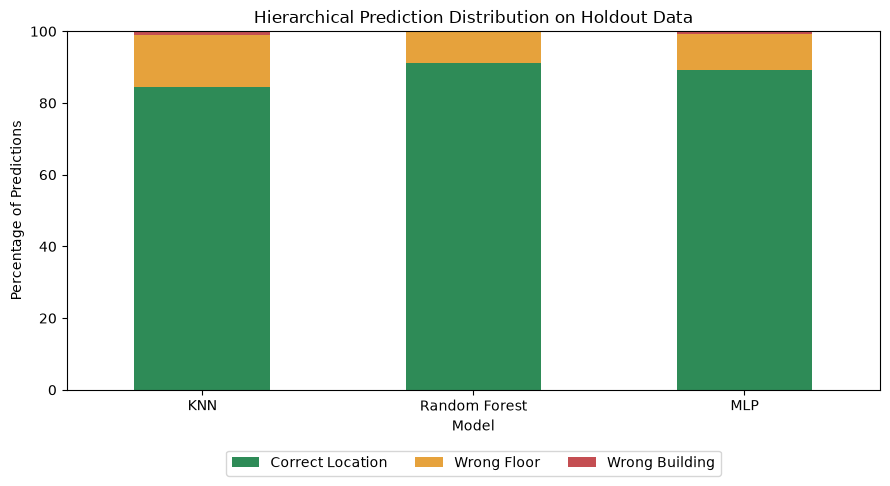

In [50]:
error_columns = [
    "Joint Accuracy (%)",
    "Wrong Floor (%)",
    "Wrong Building (%)"
]

holdout_errors.set_index("Model")[error_columns].plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["#2E8B57", "#E6A23C", "#C44E52"]
)

plt.title("Hierarchical Prediction Distribution on Holdout Data")
plt.xlabel("Model")
plt.ylabel("Percentage of Predictions")
plt.ylim(0, 100)
plt.xticks(rotation=0)

plt.legend(
    ["Correct Location", "Wrong Floor", "Wrong Building"],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=3
)

plt.tight_layout()
results_dir = Path("results/hierarchical_analysis")
results_dir.mkdir(parents=True, exist_ok=True)
plt.show()

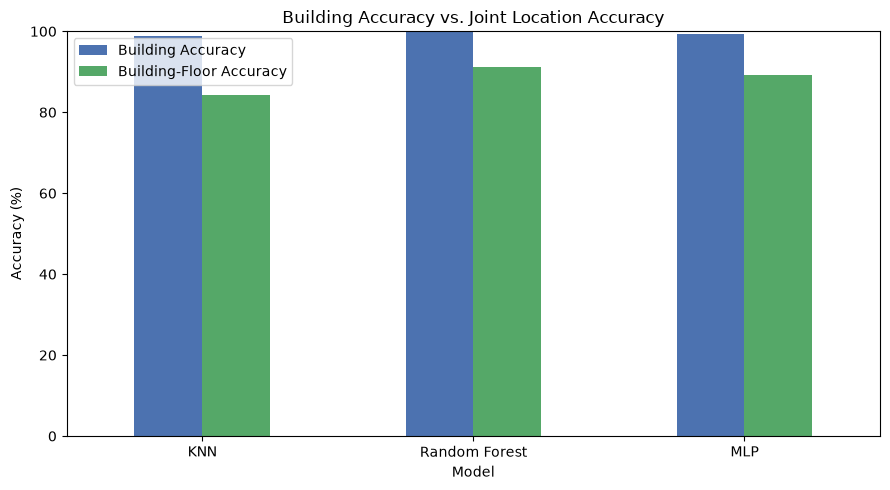

In [49]:
holdout_errors.set_index("Model")[
    ["Building Accuracy (%)", "Joint Accuracy (%)"]
].plot(
    kind="bar",
    figsize=(9, 5),
    color=["#4C72B0", "#55A868"]
)

plt.title("Building Accuracy vs. Joint Location Accuracy")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(["Building Accuracy", "Building-Floor Accuracy"])
plt.tight_layout()
results_dir = Path("results/hierarchical_analysis")
results_dir.mkdir(parents=True, exist_ok=True)
plt.show()

### 6.2 Observations

All three models achieved higher building-level accuracy than joint
building-floor accuracy on the official holdout dataset. Most of the
incorrect predictions occurred when the model identified the correct
building but predicted the wrong floor.

Random Forest performed the best overall, followed by MLP and KNN.
KNN had the largest proportion of incorrect floor predictions.

These results suggest that Wi-Fi signal patterns are more distinguishable
between buildings than between floors within the same building. One
possible explanation is that access points on nearby floors may have
overlapping signal coverage.

Therefore, improving floor-level classification would be an important
area of focus for improving overall indoor localization performance.

## 7. Cross-Floor Misclassification Analysis

The hierarchical analysis showed that most classification errors
occurred within the correct building. To investigate these errors
further, the actual and predicted building-floor combinations are
compared.

The analysis focuses on the most frequently misclassified floor pairs
and the distance between the actual and predicted floors.

In [40]:
cross_floor_results = []

for model_name, (_, holdout_pred) in predictions.items():

    for actual, predicted in zip(y_holdout, holdout_pred):

        actual_building, actual_floor = actual.split("_")
        pred_building, pred_floor = predicted.split("_")

        if actual_building == pred_building and actual_floor != pred_floor:

            floor_difference = abs(
                int(actual_floor[1:]) - int(pred_floor[1:])
            )

            cross_floor_results.append({
                "Model": model_name,
                "Building": actual_building,
                "Actual Location": actual,
                "Predicted Location": predicted,
                "Floor Difference": floor_difference
            })

cross_floor_df = pd.DataFrame(cross_floor_results)

display(cross_floor_df.head(10))

,Model,Building,Actual Location,Predicted Location,Floor Difference
0,KNN,B1,B1_F1,B1_F3,2
1,KNN,B1,B1_F3,B1_F2,1
2,KNN,B0,B0_F1,B0_F0,1
3,KNN,B0,B0_F1,B0_F0,1
4,KNN,B0,B0_F2,B0_F0,2
5,KNN,B0,B0_F2,B0_F1,1
6,KNN,B1,B1_F0,B1_F1,1
7,KNN,B1,B1_F0,B1_F1,1
8,KNN,B0,B0_F1,B0_F0,1
9,KNN,B0,B0_F2,B0_F1,1


In [41]:
floor_pairs = cross_floor_df.groupby(
    ["Model", "Actual Location", "Predicted Location"]
).size().reset_index(name="Count")

floor_pairs = floor_pairs.sort_values(
    ["Model", "Count"],
    ascending=[True, False]
)

for model_name in predictions:

    print("\n", model_name)

    display(
        floor_pairs[floor_pairs["Model"] == model_name]
        .head(10)
        .reset_index(drop=True)
    )


 KNN


,Model,Actual Location,Predicted Location,Count
0,KNN,B1_F1,B1_F2,46
1,KNN,B1_F2,B1_F3,15
2,KNN,B0_F3,B0_F2,12
3,KNN,B0_F1,B0_F0,10
4,KNN,B0_F2,B0_F3,7
5,KNN,B2_F2,B2_F3,7
6,KNN,B2_F4,B2_F3,7
7,KNN,B0_F2,B0_F1,6
8,KNN,B0_F1,B0_F2,5
9,KNN,B2_F1,B2_F0,5



 Random Forest


,Model,Actual Location,Predicted Location,Count
0,Random Forest,B1_F1,B1_F2,45
1,Random Forest,B2_F4,B2_F3,9
2,Random Forest,B2_F2,B2_F3,7
3,Random Forest,B0_F1,B0_F0,4
4,Random Forest,B0_F2,B0_F1,4
5,Random Forest,B1_F0,B1_F2,4
6,Random Forest,B1_F3,B1_F2,3
7,Random Forest,B2_F0,B2_F1,3
8,Random Forest,B0_F0,B0_F1,2
9,Random Forest,B0_F3,B0_F2,2



 MLP


,Model,Actual Location,Predicted Location,Count
0,MLP,B1_F1,B1_F2,34
1,MLP,B0_F1,B0_F2,12
2,MLP,B0_F3,B0_F2,10
3,MLP,B2_F2,B2_F1,7
4,MLP,B0_F0,B0_F1,6
5,MLP,B0_F1,B0_F0,5
6,MLP,B0_F2,B0_F1,5
7,MLP,B1_F0,B1_F1,4
8,MLP,B1_F1,B1_F0,4
9,MLP,B2_F3,B2_F4,4


In [42]:
floor_distance_summary = cross_floor_df.groupby(
    ["Model", "Floor Difference"]
).size().unstack(fill_value=0)

display(floor_distance_summary)

Floor Difference,1,2,3,4
Model,,,,
KNN,146,13,1,1
MLP,104,7,0,0
Random Forest,90,6,1,1


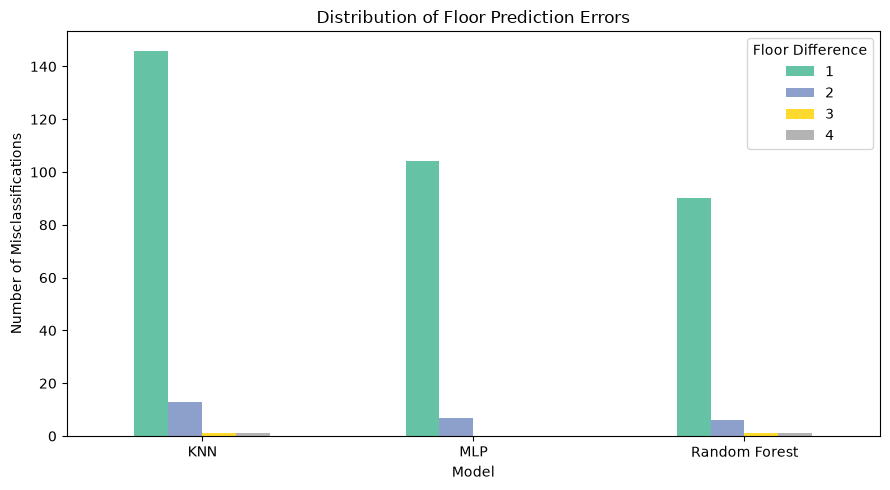

In [48]:
floor_distance_summary.plot(
    kind="bar",
    figsize=(9, 5),
    colormap="Set2"
)

plt.title("Distribution of Floor Prediction Errors")
plt.xlabel("Model")
plt.ylabel("Number of Misclassifications")
plt.xticks(rotation=0)
plt.legend(title="Floor Difference")
plt.tight_layout()
results_dir = Path("results/hierarchical_analysis")
results_dir.mkdir(parents=True, exist_ok=True)
plt.show()

In [44]:
floor_error_summary = cross_floor_df.groupby("Model").agg(
    Total_Floor_Errors=("Floor Difference", "count"),
    Mean_Floor_Error=("Floor Difference", "mean"),
    Median_Floor_Error=("Floor Difference", "median"),
    Maximum_Floor_Error=("Floor Difference", "max")
)

display(floor_error_summary.round(4))

,Total_Floor_Errors,Mean_Floor_Error,Median_Floor_Error,Maximum_Floor_Error
Model,,,,
KNN,161,1.1118,1.0,4
MLP,111,1.0631,1.0,2
Random Forest,98,1.1122,1.0,4


## 8. Building-Level Confusion Matrices

The original confusion matrices evaluate all 13 building-floor
classes. Building-level confusion matrices are generated separately
to examine misclassifications between the three buildings without
considering floor labels.

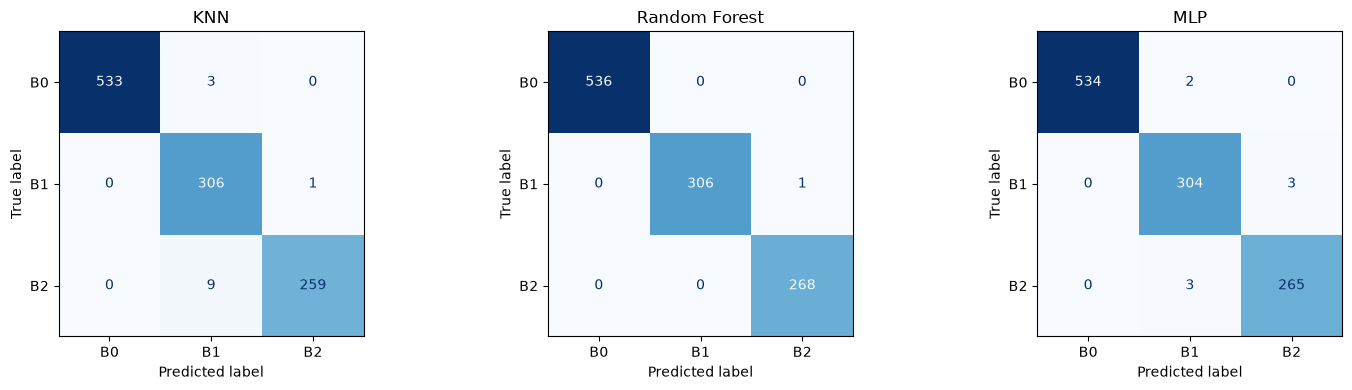

In [47]:
from sklearn.metrics import ConfusionMatrixDisplay

building_labels = ["B0", "B1", "B2"]

true_buildings = [
    label.split("_")[0] for label in y_holdout
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (model_name, (_, holdout_pred)) in zip(
    axes, predictions.items()
):

    pred_buildings = [
        label.split("_")[0] for label in holdout_pred
    ]

    cm = confusion_matrix(
        true_buildings,
        pred_buildings,
        labels=building_labels
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=building_labels
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(model_name)

plt.tight_layout()
results_dir = Path("results/hierarchical_analysis")
results_dir.mkdir(parents=True, exist_ok=True)
plt.show()

## 9. Results and Observations

### Building-Level Performance

All three models performed well when predicting the building.
KNN achieved a building-level accuracy of 98.83%, Random Forest
achieved 99.91%, and MLP achieved 99.28%.

Random Forest incorrectly classified only one building out of
1,111 holdout samples. This shows that most localization errors
were caused by incorrect floor predictions rather than incorrect
building predictions.

### Cross-Floor Misclassifications

The most frequently confused location pair across all three
models was B1_F1 and B1_F2, specifically when B1_F1 was predicted
as B1_F2. This occurred 46 times for KNN, 45 times for Random
Forest, and 34 times for MLP.

Since the same pattern was observed across different models,
the Wi-Fi fingerprints of these two floors may have similar
characteristics. Further investigation of their signal
distributions would be needed to confirm this.

### Floor Error Distance

Most incorrect floor predictions were only one floor away from
the actual location. Approximately 90.68% of KNN's floor errors,
91.84% of Random Forest's floor errors, and 93.69% of MLP's
floor errors were between adjacent floors.

Although Random Forest had the fewest overall errors, MLP
had the lowest average floor error distance of 1.0631.
MLP also had a maximum floor error of two floors, compared
to four floors for KNN and Random Forest.

These results indicate that distinguishing between nearby
floors remains a major challenge in Wi-Fi-based indoor
localization.

### Overall Findings

Random Forest achieved the highest overall classification
accuracy and the lowest number of building and floor errors.
However, MLP produced less severe floor errors when incorrect
floor predictions occurred within the correct building.

The results suggest that future improvements should focus
on distinguishing between adjacent floors, particularly
within Building 1.

## 10. Export Results

The results of the hierarchical and cross-floor error analyses
are saved as CSV files for use in the final report.

In [46]:
results_dir = Path("results/hierarchical_analysis")
results_dir.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    results_dir / "model_performance.csv",
    index=False
)

hierarchical_df.to_csv(
    results_dir / "hierarchical_errors.csv",
    index=False
)

cross_floor_df.to_csv(
    results_dir / "cross_floor_errors.csv",
    index=False
)

floor_pairs.to_csv(
    results_dir / "confused_floor_pairs.csv",
    index=False
)

floor_distance_summary.to_csv(
    results_dir / "floor_distance_distribution.csv"
)

floor_error_summary.to_csv(
    results_dir / "floor_error_summary.csv"
)

print("All analysis results saved successfully.")

for file in results_dir.glob("*.csv"):
    print(file.name)

All analysis results saved successfully.
floor_distance_distribution.csv
model_performance.csv
confused_floor_pairs.csv
floor_error_summary.csv
hierarchical_errors.csv
cross_floor_errors.csv
